## 1. Patrones almacenados

Se construyen las letras J y H como imágenes binarias de $8\times 8$ píxeles, donde $+1$ representa un píxel activo y $-1$ uno inactivo. Cada imagen se aplana en un vector de $N = 64$ componentes, y los dos patrones se organizan en la matriz $X$ de tamaño $P\times N = 2\times 64$:

$$X = \begin{pmatrix}\mathbf{x}_J\\ \mathbf{x}_H\end{pmatrix}, \qquad x_{\mu i}\in\{-1, +1\}$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

Tamaño de X: (2, 64)


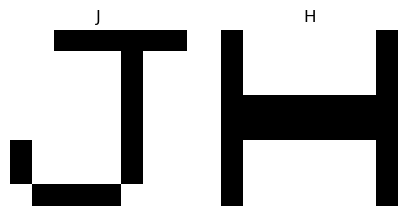

In [ ]:
# 8 líneas de 8 caracteres
J = ["..######",
     ".....#..",
     ".....#..",
     ".....#..",
     ".....#..",
     "#....#..",
     "#....#..",
     ".####..."]

H = ["#......#",
     "#......#",
     "#......#",
     "########",
     "########",
     "#......#",
     "#......#",
     "#......#"]

def a_vector(filas): # Convierte la imagen en texto a un vector de ±1 ('#' = +1, '.' = -1)
    return np.array([[1 if c == "#" else -1 for c in f] for f in filas]).reshape(-1)

X = np.vstack([a_vector(J), a_vector(H)]).astype(float)   # matriz (2, 64)
P, N = X.shape
print("Tamaño de X:", X.shape)

fig, ax = plt.subplots(1, 2, figsize=(5, 2.5))
for a_, x, nombre in zip(ax, X, ["J", "H"]):
    a_.imshow(x.reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1)
    a_.set_title(nombre)
    a_.axis("off")
plt.show()

In [4]:
print(X.shape)            # (2, 64)
print(X[0].reshape(8, 8)) # la J como matriz 8x8 de ±1

(2, 64)
[[-1. -1.  1.  1.  1.  1.  1.  1.]
 [-1. -1. -1. -1. -1.  1. -1. -1.]
 [-1. -1. -1. -1. -1.  1. -1. -1.]
 [-1. -1. -1. -1. -1.  1. -1. -1.]
 [-1. -1. -1. -1. -1.  1. -1. -1.]
 [ 1. -1. -1. -1. -1.  1. -1. -1.]
 [ 1. -1. -1. -1. -1.  1. -1. -1.]
 [-1.  1.  1.  1.  1. -1. -1. -1.]]


## 2. Energía y regla de actualización

La energía de la red es

$$E(\mathbf{q}) = \frac{1}{2}\sum_{i=1}^{N}q_i^2 - \frac{1}{\beta}\ln\left(\sum_{\mu=1}^{P}\exp\Big[\beta\sum_{i=1}^{N}x_{\mu i}q_i\Big]\right)$$

y la regla de actualización obtenida en la parte analítica (ecuación [13]) es

$$q_i^{(t+1)} = (1-\alpha)\,q_i^{(t)} + \alpha\sum_{\mu=1}^{P}p_\mu^{(t)}x_{\mu i}, \qquad p_\mu^{(t)} = \frac{e^{\beta\sum_j x_{\mu j}q_j^{(t)}}}{\sum_\nu e^{\beta\sum_j x_{\nu j}q_j^{(t)}}},$$

que con $\alpha = 1$ se reduce a $\mathbf{q}^{(t+1)} = X^T\,\text{softmax}(\beta X\mathbf{q}^{(t)})$.

Se itera hasta que $\max_i|q_i^{(t+1)} - q_i^{(t)}| < 10^{-8}$ (convergencia) o hasta un número máximo de iteraciones.

Funciones auxiliares:
- `perturbar`: invierte el signo de un porcentaje aleatorio de píxeles del patrón.
- `precision`: convierte el estado final en binario según el signo de cada componente y calcula el porcentaje de píxeles que coinciden con el patrón original.

In [5]:
def softmax(z):
    z = z - np.max(z)                  # se resta el máximo para evitar desbordamientos
    e = np.exp(z)
    return e / e.sum()

def energia(q, X, beta):
    m = beta * (X @ q)                 # β · solapamientos con cada patrón
    lse = np.max(m) + np.log(np.sum(np.exp(m - np.max(m))))   # ln Σ exp(m), estable
    return 0.5 * q @ q - lse / beta

def recuperar(q0, X, beta, alpha=1.0, max_iter=500, tol=1e-8):
    q = q0.astype(float).copy()
    E_hist = [energia(q, X, beta)]
    for _ in range(max_iter):
        p = softmax(beta * (X @ q))            # pesos p_μ
        q_nuevo = q - alpha * (q - X.T @ p)    # q - α ∂E/∂q
        E_hist.append(energia(q_nuevo, X, beta))
        if np.max(np.abs(q_nuevo - q)) < tol:  # convergencia
            q = q_nuevo
            break
        q = q_nuevo
    return q, E_hist

def perturbar(x, frac, rng):
    q = x.copy()
    idx = rng.choice(len(x), int(round(frac * len(x))), replace=False)
    q[idx] *= -1                       # invierte los píxeles elegidos
    return q

def precision(q, x):
    return np.mean(np.sign(q) == x) * 100

## 3. Experimento (a): patrón original, perturbado y estado final

Se toma la letra J, se invierte aleatoriamente el 20 % de sus píxeles y se aplica la regla de actualización con $\alpha = 1$ y $\beta = 0.5$. Se muestran el patrón original, el estado inicial perturbado y el estado final de la red, tanto en su representación continua como binaria (signo de cada componente).

Precisión de la recuperación = 100.0 %
Iteraciones hasta converger  = 2


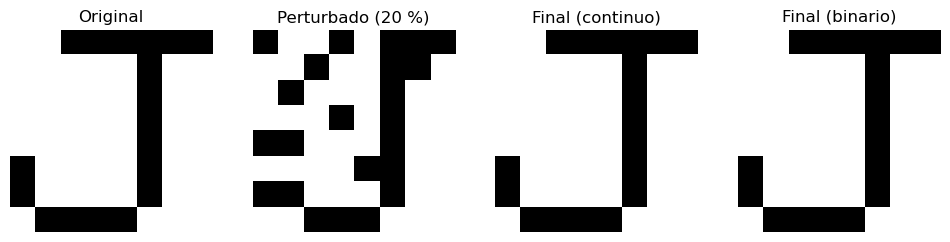

In [6]:
rng = np.random.default_rng(0)
beta = 0.5

q0 = perturbar(X[0], 0.20, rng)          # J con 20 % de píxeles invertidos
qf, E_hist = recuperar(q0, X, beta)

print(f"Precisión de la recuperación = {precision(qf, X[0]):.1f} %")
print(f"Iteraciones hasta converger  = {len(E_hist) - 1}")

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
imagenes = [X[0], q0, qf, np.sign(qf)]
titulos  = ["Original", "Perturbado (20 %)", "Final (continuo)", "Final (binario)"]
for a_, img, tit in zip(ax, imagenes, titulos):
    a_.imshow(img.reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1)
    a_.set_title(tit)
    a_.axis("off")
plt.show()

## 4. Experimento (b): efecto del porcentaje de píxeles perturbados

Para porcentajes de perturbación entre 0 % y 60 % (en pasos de 5 %), se generan 50 perturbaciones aleatorias distintas de la letra J, se aplica la regla de actualización y se calcula la precisión de cada recuperación. Se grafica la precisión promedio con su desviación estándar, para dos valores de $\beta$.

β = 0.05: precisión media = [100.  100.  100.  100.  100.  100.  100.  100.   96.6  77.5  69.6  48.2
  46. ]
β = 0.5: precisión media = [100.  100.  100.  100.  100.  100.  100.  100.   93.2  84.2  67.4  56.1
  46. ]


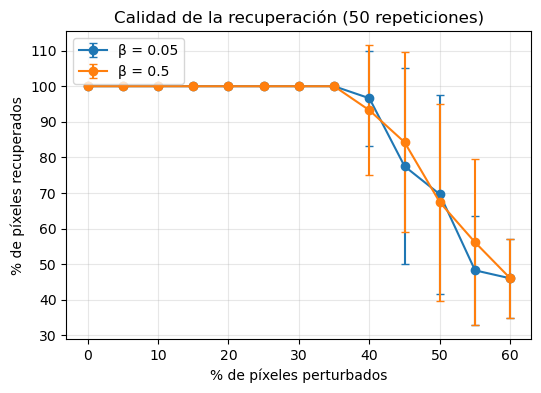

In [7]:
fracs = np.arange(0, 0.65, 0.05)        # 0 %, 5 %, ..., 60 %
n_rep = 50                               # perturbaciones por porcentaje

plt.figure(figsize=(6, 4))
for beta in [0.05, 0.5]:
    media, desv = [], []
    for f in fracs:
        accs = [precision(recuperar(perturbar(X[0], f, rng), X, beta)[0], X[0])
                for _ in range(n_rep)]
        media.append(np.mean(accs))
        desv.append(np.std(accs))
    plt.errorbar(fracs*100, media, yerr=desv, marker="o", capsize=3, label=f"β = {beta}")
    print(f"β = {beta}: precisión media =", np.round(media, 1))

plt.xlabel("% de píxeles perturbados")
plt.ylabel("% de píxeles recuperados")
plt.title(f"Calidad de la recuperación ({n_rep} repeticiones)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Experimento (c): efecto de $\beta$

Con el mismo estado inicial (la J con el 20 % de píxeles invertidos), se aplica la regla de actualización para varios valores de $\beta$ y se comparan:

- la evolución de la energía durante las iteraciones (como el valor de $E$ depende de $\beta$, se grafica $E(t) - E_{\text{final}}$ para poder comparar),
- el estado final continuo de la red,
- la distancia entre el estado final y el patrón original, en función de $\beta$.

β = 0.01: iteraciones = 19, pesos finales (J, H) = [0.5 0.5], precisión = 100.0 %
β = 0.03: iteraciones = 92, pesos finales (J, H) = [0.729 0.271], precisión = 100.0 %
β = 0.05: iteraciones = 14, pesos finales (J, H) = [0.966 0.034], precisión = 100.0 %
β = 0.1: iteraciones = 6, pesos finales (J, H) = [0.999 0.001], precisión = 100.0 %
β = 0.5: iteraciones = 2, pesos finales (J, H) = [1. 0.], precisión = 100.0 %


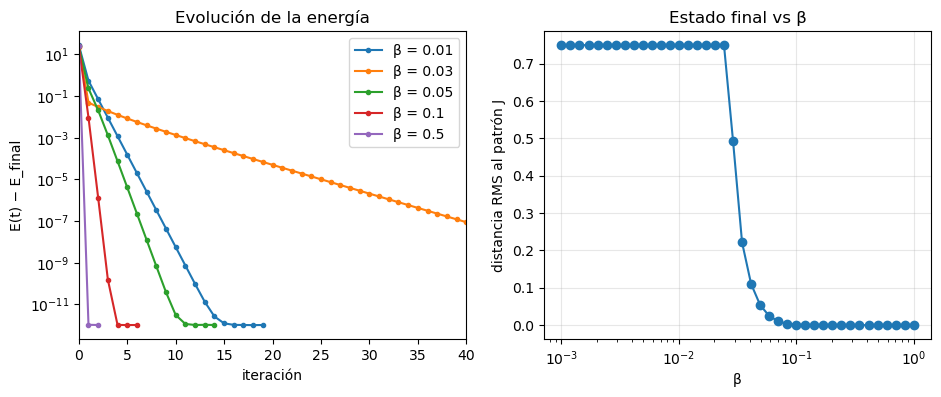

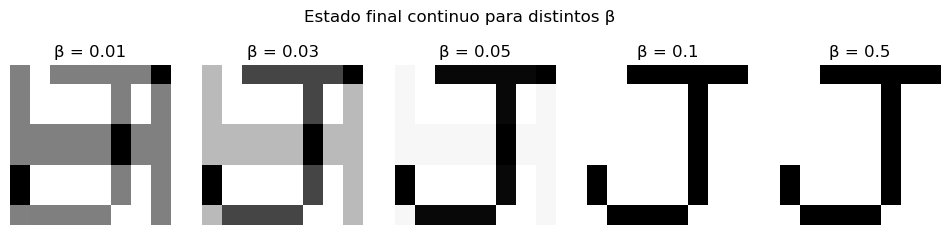

In [8]:
q0 = perturbar(X[0], 0.20, np.random.default_rng(1))
betas = [0.01, 0.03, 0.05, 0.1, 0.5]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fig2, ax2 = plt.subplots(1, len(betas), figsize=(12, 2.8))

for k, beta in enumerate(betas):
    qf, E = recuperar(q0, X, beta)
    E = np.array(E)
    p = softmax(beta * (X @ qf))
    print(f"β = {beta}: iteraciones = {len(E)-1}, pesos finales (J, H) = {np.round(p, 3)}, "
          f"precisión = {precision(qf, X[0]):.1f} %")

    # energía
    ax[0].plot(E - E[-1] + 1e-12, marker=".", label=f"β = {beta}")
    # estado final continuo
    ax2[k].imshow(qf.reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1)
    ax2[k].set_title(f"β = {beta}")
    ax2[k].axis("off")

ax[0].set_yscale("log")
ax[0].set_xlim(0, 40)
ax[0].set(xlabel="iteración", ylabel="E(t) − E_final", title="Evolución de la energía")
ax[0].legend()

# distancia al patrón J en función de β
bs = np.logspace(-3, 0, 40)
dist = [np.linalg.norm(recuperar(q0, X, b)[0] - X[0]) / np.sqrt(N) for b in bs]
ax[1].semilogx(bs, dist, "o-")
ax[1].set(xlabel="β", ylabel="distancia RMS al patrón J", title="Estado final vs β")
ax[1].grid(alpha=0.3)

fig2.suptitle("Estado final continuo para distintos β")
plt.show()

Se observa que en todos los casos la energía disminuye en cada iteración hasta estabilizarse, como se espera del descenso de gradiente. Lo que cambia con $\beta$ es la rapidez y el resultado final.

Para $\beta$ pequeño (menor a 0.03), se oberva que la red no logra decidirse entre la J y la H, el estado final es una mezcla de las dos letras y queda lejos del patrón original. Alrededor de $\beta \approx 0.03$ ocurre un cambio abrupto, donde la red tarda más en converger. Para $\beta \geq 0.1$, la red recupera la J de forma exacta y en muy pocas iteraciones.

Podría decirse que $\beta$ controla la medida de desición de la red, pues con valores bajos promedia los recuerdos, y con valores altos elige el patrón más parecido al estado inicial.